In [1]:
!pip install pandas numpy matplotlib seaborn scipy statsmodels

   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB 487.6 kB/s eta 0:00:24
   ---------------------------------------- 0.0/11.3 MB 487.6 kB/s eta 0:00:24
   ---------------------------------------- 0.0/11.3 MB 487.6 kB/s eta 0:00:24
   ---------------------------------------- 0.1/11.3 MB 272.3 kB/s eta 0:00:42
   ---------------------------------------- 0.1/11.3 MB 272.3 kB/s eta 0:00:42
   ---------------------------------------- 0.1/11.3 MB 245.8 kB/s eta 0:00:46
   ---------------------------------------- 0.1/11.3 MB 249.0 kB/s eta 0:00:46
   ---------------------------------------- 0.1/11.3 MB 249.0 kB/s eta 0:00:46
   ---------------------------------------- 0.1/11.3 MB 249.0 kB/s eta 0:00:46
   ---------------------------------------- 0.1/11.3 MB 210.4 kB/s eta 0:00:54
   ---------------------------------------- 0.1/11.3 MB 210.4 kB/s eta


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:
data = pd.read_csv("archive/data.csv")
labels = pd.read_csv("archive/labels.csv")

print("Data shape:", data.shape)
print("Labels shape:", labels.shape)

Data shape: (801, 20532)
Labels shape: (801, 2)


In [3]:
print("First 5 rows of expression data:")
display(data.head())

print("\nFirst 5 rows of labels:")
display(labels.head())

First 5 rows of expression data:


,Unnamed: 0,gene_0,gene_1,gene_2,gene_3,gene_4,gene_5,gene_6,gene_7,gene_8,...,gene_20521,gene_20522,gene_20523,gene_20524,gene_20525,gene_20526,gene_20527,gene_20528,gene_20529,gene_20530
0,sample_0,0.0,2.017209,3.265527,5.478487,10.431999,0.0,7.175175,0.591871,0.0,...,4.926711,8.210257,9.723516,7.220030,9.119813,12.003135,9.650743,8.921326,5.286759,0.0
1,sample_1,0.0,0.592732,1.588421,7.586157,9.623011,0.0,6.816049,0.000000,0.0,...,4.593372,7.323865,9.740931,6.256586,8.381612,12.674552,10.517059,9.397854,2.094168,0.0
2,sample_2,0.0,3.511759,4.327199,6.881787,9.870730,0.0,6.972130,0.452595,0.0,...,5.125213,8.127123,10.908640,5.401607,9.911597,9.045255,9.788359,10.090470,1.683023,0.0
3,sample_3,0.0,3.663618,4.507649,6.659068,10.196184,0.0,7.843375,0.434882,0.0,...,6.076566,8.792959,10.141520,8.942805,9.601208,11.392682,9.694814,9.684365,3.292001,0.0
4,sample_4,0.0,2.655741,2.821547,6.539454,9.738265,0.0,6.566967,0.360982,0.0,...,5.996032,8.891425,10.373790,7.181162,9.846910,11.922439,9.217749,9.461191,5.110372,0.0



First 5 rows of labels:


,Unnamed: 0,Class
0,sample_0,PRAD
1,sample_1,LUAD
2,sample_2,PRAD
3,sample_3,PRAD
4,sample_4,BRCA


In [4]:
data = data.drop(columns=["Unnamed: 0"])
labels = labels.drop(columns=["Unnamed: 0"])

print("Data shape:", data.shape)
print("Labels shape:", labels.shape)

Data shape: (801, 20531)
Labels shape: (801, 1)


In [5]:
data["Class"] = labels["Class"]

print(data.head())

   gene_0    gene_1    gene_2    gene_3     gene_4  gene_5    gene_6  \
0     0.0  2.017209  3.265527  5.478487  10.431999     0.0  7.175175   
1     0.0  0.592732  1.588421  7.586157   9.623011     0.0  6.816049   
2     0.0  3.511759  4.327199  6.881787   9.870730     0.0  6.972130   
3     0.0  3.663618  4.507649  6.659068  10.196184     0.0  7.843375   
4     0.0  2.655741  2.821547  6.539454   9.738265     0.0  6.566967   

     gene_7  gene_8  gene_9  ...  gene_20522  gene_20523  gene_20524  \
0  0.591871     0.0     0.0  ...    8.210257    9.723516    7.220030   
1  0.000000     0.0     0.0  ...    7.323865    9.740931    6.256586   
2  0.452595     0.0     0.0  ...    8.127123   10.908640    5.401607   
3  0.434882     0.0     0.0  ...    8.792959   10.141520    8.942805   
4  0.360982     0.0     0.0  ...    8.891425   10.373790    7.181162   

   gene_20525  gene_20526  gene_20527  gene_20528  gene_20529  gene_20530  \
0    9.119813   12.003135    9.650743    8.921326    5.28

In [6]:
print("Cancer types and sample counts:")

print(data["Class"].value_counts())

Cancer types and sample counts:
Class
BRCA    300
KIRC    146
LUAD    141
PRAD    136
COAD     78
Name: count, dtype: int64


In [7]:
print("Total missing values:")

print(data.isnull().sum().sum())

Total missing values:
0


In [8]:
print("Duplicate rows:")

print(data.duplicated().sum())

Duplicate rows:
0


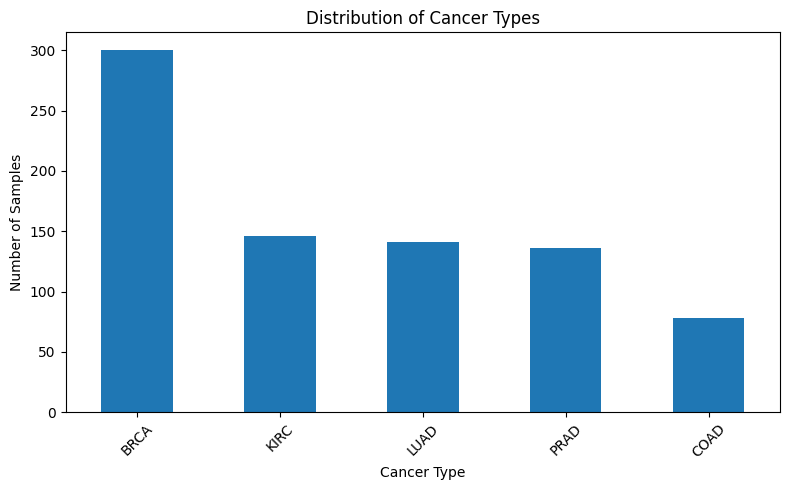

In [9]:
plt.figure(figsize=(8, 5))

data["Class"].value_counts().plot(kind="bar")

plt.title("Distribution of Cancer Types")
plt.xlabel("Cancer Type")
plt.ylabel("Number of Samples")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [10]:
gene_columns = [
    column for column in data.columns
    if column != "Class"
]

print("Number of genes:", len(gene_columns))

print("\nFirst 10 genes:")
print(gene_columns[:10])

Number of genes: 20531

First 10 genes:
['gene_0', 'gene_1', 'gene_2', 'gene_3', 'gene_4', 'gene_5', 'gene_6', 'gene_7', 'gene_8', 'gene_9']


In [11]:
group1 = "PRAD"
group2 = "LUAD"

prad = data[data["Class"] == group1]
luad = data[data["Class"] == group2]

print("PRAD samples:", len(prad))
print("LUAD samples:", len(luad))

PRAD samples: 136
LUAD samples: 141


In [12]:
prad_expression = prad[gene_columns].astype(float)

luad_expression = luad[gene_columns].astype(float)

print("PRAD expression shape:",
      prad_expression.shape)

print("LUAD expression shape:",
      luad_expression.shape)

PRAD expression shape: (136, 20531)
LUAD expression shape: (141, 20531)


In [13]:
prad_mean = prad_expression.mean(axis=0)

luad_mean = luad_expression.mean(axis=0)

print("PRAD mean:")
print(prad_mean.head())

print("\nLUAD mean:")
print(luad_mean.head())

PRAD mean:
gene_0    0.026544
gene_1    3.441041
gene_2    3.971262
gene_3    6.662433
gene_4    9.752363
dtype: float64

LUAD mean:
gene_0    0.041088
gene_1    3.358260
gene_2    3.457701
gene_3    6.625187
gene_4    9.781486
dtype: float64


In [14]:

log2_fold_change = prad_mean - luad_mean

print(log2_fold_change.head())


gene_0   -0.014544
gene_1    0.082781
gene_2    0.513561
gene_3    0.037246
gene_4   -0.029123
dtype: float64


In [15]:
p_values = []

for gene in gene_columns:

    prad_values = prad_expression[gene]
    luad_values = luad_expression[gene]

    statistic, p_value = ttest_ind(
        prad_values,
        luad_values,
        equal_var=False
    )

    p_values.append(p_value)

print("Statistical testing completed!")

Statistical testing completed!


In [16]:
results = pd.DataFrame({

    "Gene": gene_columns,

    "PRAD_Mean": prad_mean.values,

    "LUAD_Mean": luad_mean.values,

    "Log2_Fold_Change": log2_fold_change.values,

    "P_Value": p_values
})

display(results.head())

,Gene,PRAD_Mean,LUAD_Mean,Log2_Fold_Change,P_Value
0,gene_0,0.026544,0.041088,-0.014544,0.416589
1,gene_1,3.441041,3.358260,0.082781,0.553603
2,gene_2,3.971262,3.457701,0.513561,0.000027
3,gene_3,6.662433,6.625187,0.037246,0.507461
4,gene_4,9.752363,9.781486,-0.029123,0.589084


In [17]:
results["Adjusted_P_Value"] = multipletests(
    results["P_Value"],
    method="fdr_bh"
)[1]

display(results.head())

,Gene,PRAD_Mean,LUAD_Mean,Log2_Fold_Change,P_Value,Adjusted_P_Value
0,gene_0,0.026544,0.041088,-0.014544,0.416589,NaN
1,gene_1,3.441041,3.358260,0.082781,0.553603,NaN
2,gene_2,3.971262,3.457701,0.513561,0.000027,NaN
3,gene_3,6.662433,6.625187,0.037246,0.507461,NaN
4,gene_4,9.752363,9.781486,-0.029123,0.589084,NaN


In [18]:
results = results.sort_values(
    by="Adjusted_P_Value"
)

print("Top 20 genes:")

display(results.head(20))

Top 20 genes:


,Gene,PRAD_Mean,LUAD_Mean,Log2_Fold_Change,P_Value,Adjusted_P_Value
0,gene_0,0.026544,0.041088,-0.014544,4.165892e-01,NaN
1,gene_1,3.441041,3.358260,0.082781,5.536034e-01,NaN
2,gene_2,3.971262,3.457701,0.513561,2.707158e-05,NaN
3,gene_3,6.662433,6.625187,0.037246,5.074611e-01,NaN
4,gene_4,9.752363,9.781486,-0.029123,5.890839e-01,NaN
5,gene_5,0.000000,0.000000,0.000000,NaN,NaN
6,gene_6,7.807088,7.283121,0.523967,1.123733e-05,NaN
7,gene_7,0.448975,0.393179,0.055796,3.038422e-01,NaN
8,gene_8,0.007497,0.015985,-0.008488,5.242815e-01,NaN
9,gene_9,0.009264,0.000000,0.009264,3.190996e-01,NaN


In [19]:
deg = results[
    (results["Adjusted_P_Value"] < 0.05) &
    (abs(results["Log2_Fold_Change"]) >= 1)
]

print("Total Differentially Expressed Genes:",
      len(deg))

display(deg.head(20))

Total Differentially Expressed Genes: 0


,Gene,PRAD_Mean,LUAD_Mean,Log2_Fold_Change,P_Value,Adjusted_P_Value


In [20]:
upregulated = deg[
    deg["Log2_Fold_Change"] >= 1
]

print("Number of Upregulated Genes:",
      len(upregulated))

display(upregulated.head(20))

Number of Upregulated Genes: 0


,Gene,PRAD_Mean,LUAD_Mean,Log2_Fold_Change,P_Value,Adjusted_P_Value


In [21]:
downregulated = deg[
    deg["Log2_Fold_Change"] <= -1
]

print("Number of Downregulated Genes:",
      len(downregulated))

display(downregulated.head(20))

Number of Downregulated Genes: 0


,Gene,PRAD_Mean,LUAD_Mean,Log2_Fold_Change,P_Value,Adjusted_P_Value


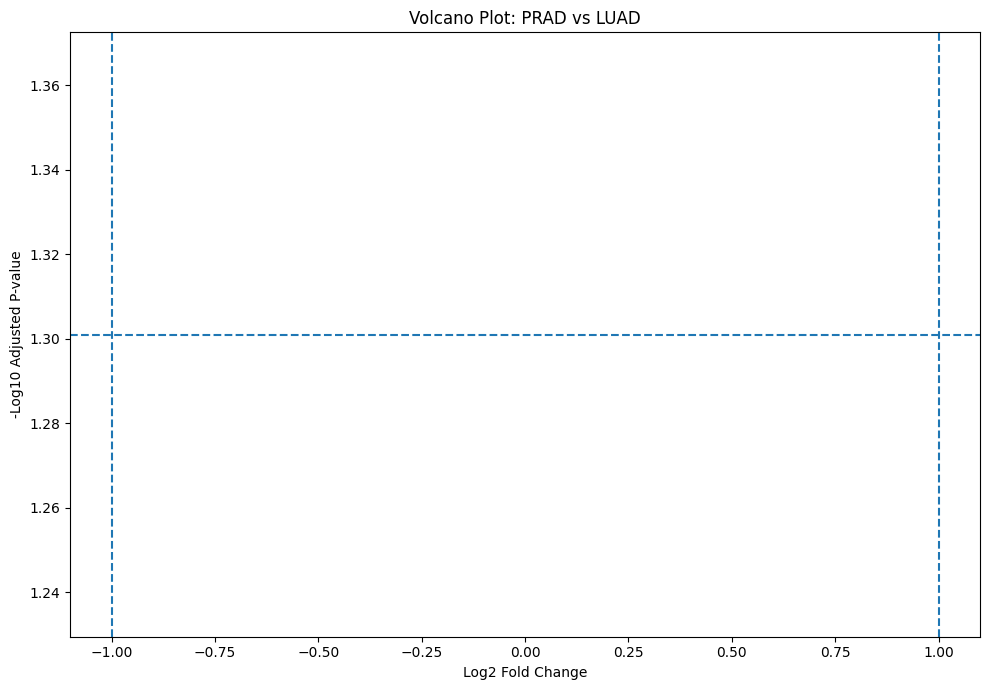

In [22]:
plt.figure(figsize=(10, 7))

x = results["Log2_Fold_Change"]

y = -np.log10(
    results["Adjusted_P_Value"] + 1e-300
)

plt.scatter(
    x,
    y,
    alpha=0.5
)

plt.axvline(
    x=1,
    linestyle="--"
)

plt.axvline(
    x=-1,
    linestyle="--"
)

plt.axhline(
    y=-np.log10(0.05),
    linestyle="--"
)

plt.xlabel("Log2 Fold Change")

plt.ylabel("-Log10 Adjusted P-value")

plt.title("Volcano Plot: PRAD vs LUAD")

plt.tight_layout()

plt.show()

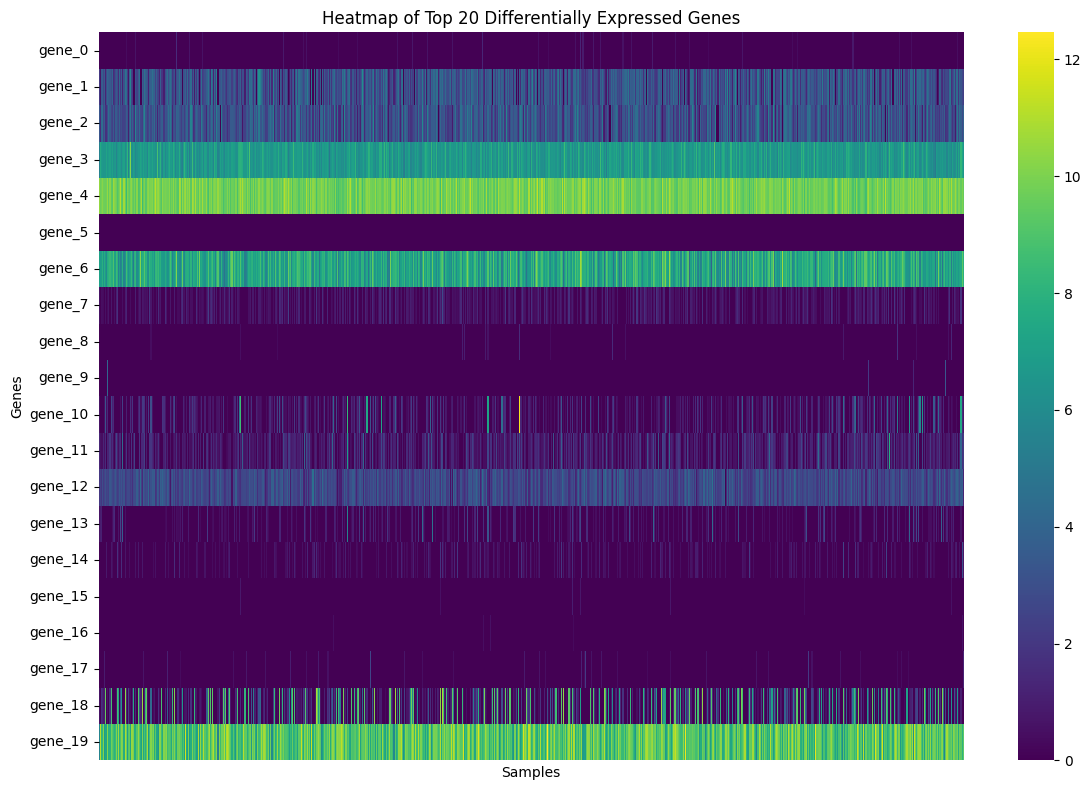

In [23]:
top_genes = results.head(20)["Gene"].tolist()

heatmap_data = data[top_genes].astype(float)

plt.figure(figsize=(12, 8))

sns.heatmap(
    heatmap_data.T,
    cmap="viridis",
    xticklabels=False
)

plt.title(
    "Heatmap of Top 20 Differentially Expressed Genes"
)

plt.xlabel("Samples")

plt.ylabel("Genes")

plt.tight_layout()

plt.show()

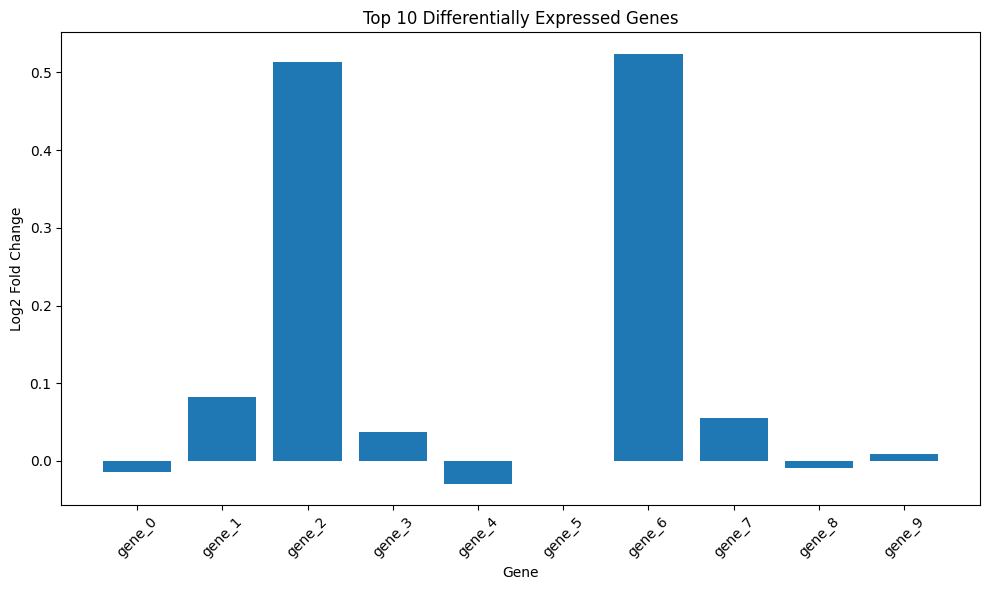

In [24]:
top10 = results.head(10)

plt.figure(figsize=(10, 6))

plt.bar(
    top10["Gene"],
    top10["Log2_Fold_Change"]
)

plt.xlabel("Gene")

plt.ylabel("Log2 Fold Change")

plt.title(
    "Top 10 Differentially Expressed Genes"
)

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

In [25]:
results.to_csv(
    "RNA_Seq_All_Gene_Results.csv",
    index=False
)

deg.to_csv(
    "Differentially_Expressed_Genes.csv",
    index=False
)

upregulated.to_csv(
    "Upregulated_Genes.csv",
    index=False
)

downregulated.to_csv(
    "Downregulated_Genes.csv",
    index=False
)

print("All results saved successfully!")

All results saved successfully!


In [26]:
print("==============================================")
print("          RNA-SEQ DATA ANALYSIS")
print("==============================================")

print("Dataset: Cancer RNA-Seq Gene Expression")

print("Comparison:", group1, "vs", group2)

print("PRAD samples:", len(prad))

print("LUAD samples:", len(luad))

print("Total genes analyzed:", len(gene_columns))

print("Differentially Expressed Genes:", len(deg))

print("Upregulated Genes:", len(upregulated))

print("Downregulated Genes:", len(downregulated))

print("==============================================")

print("Analysis completed successfully!")

          RNA-SEQ DATA ANALYSIS
Dataset: Cancer RNA-Seq Gene Expression
Comparison: PRAD vs LUAD
PRAD samples: 136
LUAD samples: 141
Total genes analyzed: 20531
Differentially Expressed Genes: 0
Upregulated Genes: 0
Downregulated Genes: 0
Analysis completed successfully!
